dw 15 w 0
dw 29.625 w -0.75
dw 9.181666992187488 w -2.23125
dw -20.035065605902062 w -2.6903333496093746
dw 27.713402403316003 w -1.6885800693142714
dw -55.790167253940496 w -3.074250189480072
dw 21.498225032582617 w -0.2847418267830468
dw 32.0315784309913 w -1.3596530784121776
dw -44.10404628467309 w -2.961231999961743
dw 29.701441330825585 w -0.7560296857280884


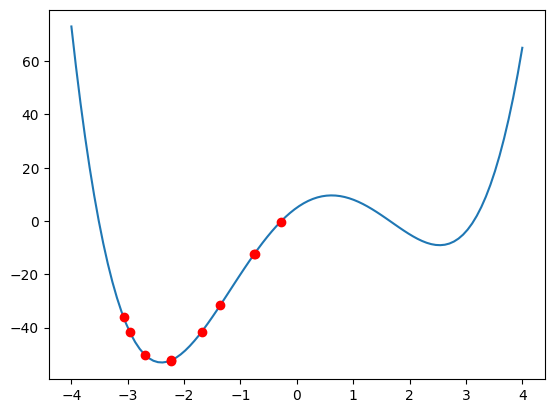

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(w):
    return w**4 - w**3 - 12*w**2 + 15*w + 5

def df(w):
    return 4*w**3 - 3*w**2 - 24*w + 15

w = np.linspace(-4, 4, 100)
plt.plot(w, f(w))

w0 = 0
eta = 0.05 # learning rate (step size)
ephochs = 10
w = w0
for i in range(ephochs):
    print('dw', df(w), 'w', w)
    w = w - eta*df(w) # actual gradient descent step
    
    plt.plot(w, f(w), 'ro')


In [7]:
import math

# Base node in a computational graph
class Node:
    def __init__(self, *inputs, value=None, name=""):
        self.inputs = list(inputs)
        self.value = value
        self.grad = 0.0
        self.name = name

    def forward(self):
        raise NotImplementedError

    def backward(self):
        raise NotImplementedError


class Constant(Node):
    # Leaf node with a fixed value; gradient can be read but is not propagated further.
    def forward(self):
        pass

    def backward(self):
        pass


class Parameter(Constant):
    # Same as Constant, but semantically marks trainable values.
    pass


class Multiply(Node):
    def forward(self):
        a = self.inputs[0].value
        b = self.inputs[1].value
        self.value = a * b

    def backward(self):
        a = self.inputs[0].value
        b = self.inputs[1].value
        self.inputs[0].grad += self.grad * b
        self.inputs[1].grad += self.grad * a


class Add(Node):
    def forward(self):
        self.value = sum(inp.value for inp in self.inputs)

    def backward(self):
        for inp in self.inputs:
            inp.grad += self.grad


class Sigmoid(Node):
    def forward(self):
        z = self.inputs[0].value
        self.value = 1.0 / (1.0 + math.exp(-z))

    def backward(self):
        s = self.value
        self.inputs[0].grad += self.grad * s * (1.0 - s)


class MSELoss(Node):
    def forward(self):
        p = self.inputs[0].value
        t = self.inputs[1].value
        self.value = (p - t) ** 2    # L = (prediction - target)^2

    def backward(self):
        p = self.inputs[0].value
        t = self.inputs[1].value
        self.inputs[0].grad += self.grad * 2.0 * (p - t)



class ComputationalGraph:
    def __init__(self, nodes_in_topo_order):
        self.nodes = nodes_in_topo_order

    def forward(self):
        for node in self.nodes:
            node.forward()
        return self.nodes[-1].value

    def backward(self):
        for node in self.nodes:
            node.grad = 0.0
        self.nodes[-1].grad = 1.0  # dL/dL
        for node in reversed(self.nodes):
            node.backward()


# Simple example: z = x0*w0 + x1*w1 + w2; y_hat = sigmoid(z); L = (y_hat - y_true)^2
x0 = Constant(value=-1.0, name="x0")
x1 = Constant(value=-2.0, name="x1")
y_true = Constant(value=0.23, name="y_true")

w0 = Parameter(value=2.0, name="w0")
w1 = Parameter(value=-3.0, name="w1")
w2 = Parameter(value=-3.0, name="w2")

m0 = Multiply(x0, w0, name="x0*w0")
m1 = Multiply(x1, w1, name="x1*w1")
z= Add(m0, m1, w2, name="z")
y_hat = Sigmoid(z, name="y_hat")
loss = MSELoss(y_hat, y_true, name="loss")

nodes = [x0, x1, y_true, w0, w1, w2, m0, m1, z, y_hat, loss]
graph = ComputationalGraph(nodes)

loss_value = graph.forward()
graph.backward()

print(f"loss = {loss_value:.6f}")
print(f"dL/dw0 = {w0.grad:.6f}, dL/dw1 = {w1.grad:.6f}, dL/dw2 = {w2.grad:.6f}")
print(f"dL/dx0 = {x0.grad:.6f}, dL/dx1 = {x1.grad:.6f}")

# One SGD step
lr = 0.1
w0.value -= lr * w0.grad
w1.value -= lr * w1.grad
w2.value -= lr * w2.grad
print(f"updated w0={w0.value:.6f}, w1={w1.value:.6f}, w2={w2.value:.6f}")

loss = 0.251060
dL/dw0 = -0.197028, dL/dw1 = -0.394056, dL/dw2 = 0.197028
dL/dx0 = 0.394056, dL/dx1 = -0.591085
updated w0=2.019703, w1=-2.960594, w2=-3.019703


In [6]:
# PyTorch version (uses autograd)
import torch

# toy data
x0 = torch.tensor(-1.0, requires_grad=False)   # treat inputs as constants here
x1 = torch.tensor(-2.0, requires_grad=False)
y_true = torch.tensor(0.23)                     # target

# parameters (learnable)
w0 = torch.tensor(2.0, requires_grad=True)
w1 = torch.tensor(-3.0, requires_grad=True)
w2 = torch.tensor(-3.0, requires_grad=True)

lr = 0.1
for step in range(1):
    # forward
    z= x0 * w0 + x1 * w1 + w2
    y = torch.sigmoid(z)
    loss = (y - y_true).pow(2)   # MSE

    # backward (autograd)
    loss.backward()

    # read grads
    print(f"step {step:2d} loss={loss.item():.6f} grads: dw0={w0.grad.item():.6f} dw1={w1.grad.item():.6f} dw2={w2.grad.item():.6f}")

    # gradient descent update
    with torch.no_grad():
        w0 -= lr * w0.grad
        w1 -= lr * w1.grad
        w2 -= lr * w2.grad

        # zero grads
        w0.grad.zero_()
        w1.grad.zero_()
        w2.grad.zero_()


step  0 loss=0.251060 grads: dw0=-0.197028 dw1=-0.394056 dw2=0.197028


In [8]:
import math

# numeric values (scalars)
x0 = -1.0
x1 = -2.0
y_true = 0.23

# parameters we will update
w0 = 2.0
w1 = -3.0
w2 = -3.0

lr = 0.1
for step in range(1):
    # ----- forward pass -----
    z = x0 * w0 + x1 * w1 + w2         # linear
    y = 1.0 / (1.0 + math.exp(-z))     # sigmoid
    loss = (y - y_true) ** 2           # MSE

    # ----- manual backward pass -----
    # dL/dy
    dL_dy = 2.0 * (y - y_true)
    # dy/dz for sigmoid
    dy_dz = y * (1.0 - y)
    # chain rule factor dL/dz
    dL_dz = dL_dy * dy_dz

    # partials of z = x0*w0 + x1*w1 + w2
    dL_dw0 = dL_dz * x0
    dL_dw1 = dL_dz * x1
    dL_dw2 = dL_dz * 1.0

    dL_dx0 = dL_dz * w0
    dL_dx1 = dL_dz * w1

    # print
    print(f"step {step:2d} loss={loss:.6f} grads: dw0={dL_dw0:.6f} dw1={dL_dw1:.6f} dw2={dL_dw2:.6f}")

    # ----- parameter update (SGD) -----
    w0 = w0 - lr * dL_dw0
    w1 = w1 - lr * dL_dw1
    w2 = w2 - lr * dL_dw2

# final values
print("final w0, w1, w2:", w0, w1, w2)


step  0 loss=0.251060 grads: dw0=-0.197028 dw1=-0.394056 dw2=0.197028
final w0, w1, w2: 2.019702819162335 -2.96059436167533 -3.019702819162335


In [9]:
import torch

# Define variables (requires_grad=True so we can differentiate)
x = torch.tensor([[2., 1., -3.],
                  [-3., 4., 2.]], requires_grad=True)

w = torch.tensor([[3., 2., 1., -1.],
                  [2., 1., 3.,  2.],
                  [3., 2., 1., -2.]], requires_grad=True)

# Upstream gradient (∂L/∂y)
grad_y = torch.tensor([[2., 3., -3., 9.],
                       [-8., 1., 4., 6.]])

# Forward pass
y = x @ w   # matrix multiplication
loss = (grad_y * y).sum()   # scalar loss

# Backward pass (compute gradients wrt x, w)
loss.backward(retain_graph=True)

print("Gradient of L w.r.t. x")
print(x.grad)

print("Gradient of L w.r.t. w")
print(w.grad)

# ----- Jacobian of y wrt x -----
# In TF you used g.jacobian; in PyTorch we use autograd.functional.jacobian
from torch.autograd.functional import jacobian

def func_x(inp):
    return inp @ w   # function of x only

jacobian_y_x = jacobian(func_x, x)
print("Jacobian of y w.r.t. x")
print(jacobian_y_x)


Gradient of L w.r.t. x
tensor([[  0.,  16.,  -9.],
        [-24.,   9., -30.]])
Gradient of L w.r.t. w
tensor([[ 28.,   3., -18.,   0.],
        [-30.,   7.,  13.,  33.],
        [-22.,  -7.,  17., -15.]])
Jacobian of y w.r.t. x
tensor([[[[ 3.,  2.,  3.],
          [ 0.,  0.,  0.]],

         [[ 2.,  1.,  2.],
          [ 0.,  0.,  0.]],

         [[ 1.,  3.,  1.],
          [ 0.,  0.,  0.]],

         [[-1.,  2., -2.],
          [ 0.,  0.,  0.]]],


        [[[ 0.,  0.,  0.],
          [ 3.,  2.,  3.]],

         [[ 0.,  0.,  0.],
          [ 2.,  1.,  2.]],

         [[ 0.,  0.,  0.],
          [ 1.,  3.,  1.]],

         [[ 0.,  0.,  0.],
          [-1.,  2., -2.]]]])


In [10]:
import torch

# Input tensor with gradient tracking
x = torch.tensor([1., -2., 3., -1.], requires_grad=True)

# Upstream gradient (∂L/∂y)
grad_y = torch.tensor([4., -1., 5., 9.])

# Forward pass
y = torch.relu(x)              # ReLU
loss = (grad_y * y).sum()      # scalar loss

# Backward pass to get ∂L/∂x
loss.backward(retain_graph=True)

print("Jacobian of y w.r.t x")
from torch.autograd.functional import jacobian

def func_x(inp):
    return torch.relu(inp)

jacobian_y_x = jacobian(func_x, x)
print(jacobian_y_x)

print("Gradient of L w.r.t. x")
print(x.grad)


Jacobian of y w.r.t x
tensor([[1., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 0.]])
Gradient of L w.r.t. x
tensor([4., 0., 5., 0.])
